In [1]:
from pathlib import Path
import requests
import zipfile

data_path = Path("data/")
image_path = data_path/"pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} already exists ...skip downloading")

else:
    print(f"{image_path} does not exist ...creating one")
    image_path.mkdir(parents = True, exist_ok = True)
    
    with open(data_path/"pizza_steak_sushi.zip", "wb") as f :
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("downloading_pizza_steak_sushi data")
        f.write(request.content)
    
    with zipfile.ZipFile(data_path/ "pizza_steak_sushi.zip", "r") as zip_ref:
        print("unzipping pizza_steak_sushi data")
        zip_ref.extractall(image_path)

data/pizza_steak_sushi already exists ...skip downloading


In [2]:
train_dir = image_path/ "train"
test_dir = image_path/ "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [3]:
from torchvision import transforms

IMG_SIZE = 224 #same as vit paper
manual_transforms = transforms.Compose([
    transforms.Resize(size =(IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])
manual_transforms

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)

In [4]:
from torchvision import datasets

train_data = datasets.ImageFolder(root = train_dir,
                      transform = manual_transforms,
                      target_transform = None)
test_data = datasets.ImageFolder(root = test_dir,
                     transform = manual_transforms)

train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [5]:
class_names = train_data.classes
len(class_names)

3

In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32 # in vit paper 4096 but we will use 32 for our small hardware
train_dataloader = DataLoader(dataset = train_data,
                              batch_size = BATCH_SIZE,
                              shuffle = True)
test_dataloader = DataLoader(dataset = test_data,
                              batch_size = BATCH_SIZE,
                              shuffle = False)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x12379fe60>,
 ['pizza', 'steak', 'sushi'])

In [7]:
len(train_dataloader), len(test_dataloader), len(class_names)

(8, 3, 3)

In [8]:
#get a batch of images
image_batch, label_batch = next(iter(train_dataloader))
image_batch, label_batch

(tensor([[[[0.3059, 0.2980, 0.2824,  ..., 0.0431, 0.0431, 0.0549],
           [0.3137, 0.3137, 0.2784,  ..., 0.0471, 0.0588, 0.0588],
           [0.3098, 0.3059, 0.2784,  ..., 0.0510, 0.0784, 0.0980],
           ...,
           [0.0275, 0.0196, 0.0275,  ..., 0.0275, 0.0314, 0.0196],
           [0.0235, 0.0196, 0.0118,  ..., 0.0196, 0.0157, 0.0196],
           [0.0196, 0.0235, 0.0157,  ..., 0.0235, 0.0235, 0.0275]],
 
          [[0.0980, 0.1020, 0.1059,  ..., 0.0118, 0.0078, 0.0157],
           [0.1137, 0.1216, 0.1059,  ..., 0.0118, 0.0157, 0.0118],
           [0.1176, 0.1255, 0.1176,  ..., 0.0118, 0.0275, 0.0353],
           ...,
           [0.0314, 0.0235, 0.0314,  ..., 0.0196, 0.0235, 0.0118],
           [0.0275, 0.0235, 0.0157,  ..., 0.0118, 0.0078, 0.0118],
           [0.0235, 0.0275, 0.0196,  ..., 0.0157, 0.0157, 0.0196]],
 
          [[0.0549, 0.0471, 0.0392,  ..., 0.0157, 0.0118, 0.0196],
           [0.0627, 0.0667, 0.0353,  ..., 0.0118, 0.0157, 0.0118],
           [0.0627, 0.05

In [9]:
image_batch.shape, label_batch.shape

(torch.Size([32, 3, 224, 224]), torch.Size([32]))

In [10]:
#get a single image from the batch
image, label = image_batch[0], label_batch[0]
image, label

(tensor([[[0.3059, 0.2980, 0.2824,  ..., 0.0431, 0.0431, 0.0549],
          [0.3137, 0.3137, 0.2784,  ..., 0.0471, 0.0588, 0.0588],
          [0.3098, 0.3059, 0.2784,  ..., 0.0510, 0.0784, 0.0980],
          ...,
          [0.0275, 0.0196, 0.0275,  ..., 0.0275, 0.0314, 0.0196],
          [0.0235, 0.0196, 0.0118,  ..., 0.0196, 0.0157, 0.0196],
          [0.0196, 0.0235, 0.0157,  ..., 0.0235, 0.0235, 0.0275]],
 
         [[0.0980, 0.1020, 0.1059,  ..., 0.0118, 0.0078, 0.0157],
          [0.1137, 0.1216, 0.1059,  ..., 0.0118, 0.0157, 0.0118],
          [0.1176, 0.1255, 0.1176,  ..., 0.0118, 0.0275, 0.0353],
          ...,
          [0.0314, 0.0235, 0.0314,  ..., 0.0196, 0.0235, 0.0118],
          [0.0275, 0.0235, 0.0157,  ..., 0.0118, 0.0078, 0.0118],
          [0.0235, 0.0275, 0.0196,  ..., 0.0157, 0.0157, 0.0196]],
 
         [[0.0549, 0.0471, 0.0392,  ..., 0.0157, 0.0118, 0.0196],
          [0.0627, 0.0667, 0.0353,  ..., 0.0118, 0.0157, 0.0118],
          [0.0627, 0.0588, 0.0392,  ...,

In [11]:
image.shape, label

(torch.Size([3, 224, 224]), tensor(1))

Text(0.5, 1.0, 'steak')

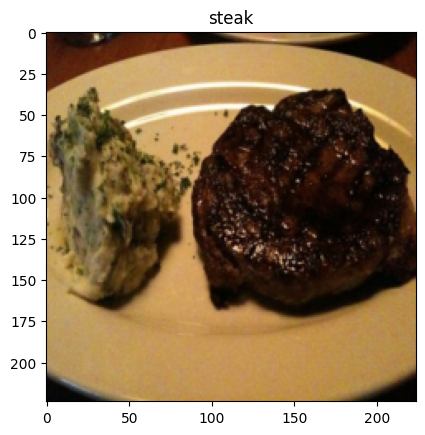

In [12]:
import matplotlib.pyplot as plt
plt.imshow(image.permute(1, 2, 0)) # c, h ,w --> h, w, c
plt.title(class_names[label])

### VIT MODEL

In [13]:
#المعطيات من الورقة البحثية
height = 224 #H
width = 224 #W
color_channel = 3 #C
patch_size = 16 #P

In [14]:
#calculate the number of patches
number_of_patches = int((height * width) / (patch_size ** 2)) # قانون من الورقة
number_of_patches #N

196

In [15]:
#input shape
embedding_layer_input_shape = (height , width , color_channel)
print(f"input shape (single 2D image) : {embedding_layer_input_shape}")

#output shape
embedding_layer_output_shape = (number_of_patches , patch_size ** 2 * color_channel) #قانون من الورقة
print(f"output shape (single 1D sequence of patches) : {embedding_layer_output_shape}")# --> (number_of_patches, embedding_dimension D)

input shape (single 2D image) : (224, 224, 3)
output shape (single 1D sequence of patches) : (196, 768)


In [16]:
16 * 16 * 3 #P**2 * c = (Embedding Dimension, D)

768

### turn a single image into patches

Text(0.5, 1.0, 'steak')

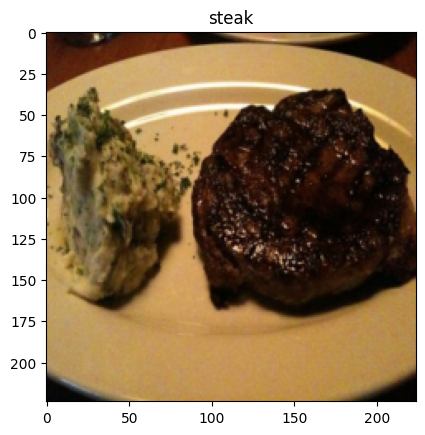

In [17]:
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])

In [18]:
image.shape

torch.Size([3, 224, 224])

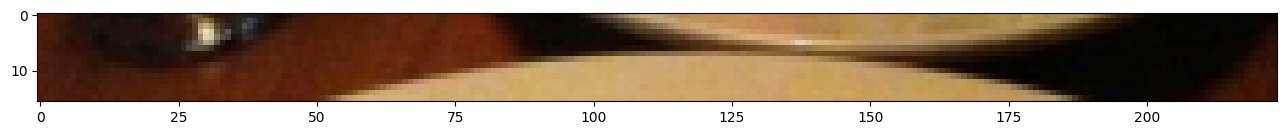

In [19]:
#get the top row of the image
permute_image = image.permute(1, 2, 0) #(H, W, C)
patch_size = 16
plt.figure(figsize=(patch_size , patch_size))
plt.imshow(permute_image[:patch_size, :, :])

In [20]:
224/16 #number of patches in one row

14.0

Number of patches per row: 14.0
Patch size: 16 pixels x 16 pixels


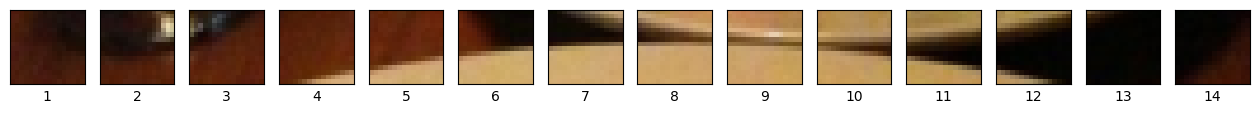

In [21]:
# Setup code to plot top row as patches
img_size = 224
patch_size = 16
num_patches = img_size / patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\nPatch size: {patch_size} pixels x {patch_size} pixels")

# Create a series of subplots
fig, axs = plt.subplots(nrows=1,
                        ncols=img_size // patch_size, # one column for each patch
                        sharex=True,
                        sharey=True,
                        figsize=(patch_size , patch_size))

# Iterate through number of patches in the top row
for i, patch in enumerate(range(0, img_size, patch_size)):
    axs[i].imshow(permute_image[:patch_size, patch:patch+patch_size, :])
    axs[i].set_xlabel(i+1) # set the patch label
    axs[i].set_xticks([])
    axs[i].set_yticks([])

Number of patches per row: 14.0
Number of patches per column: 14.0
Total patches: 196.0
Patch size: 16 pixels x 16 pixels


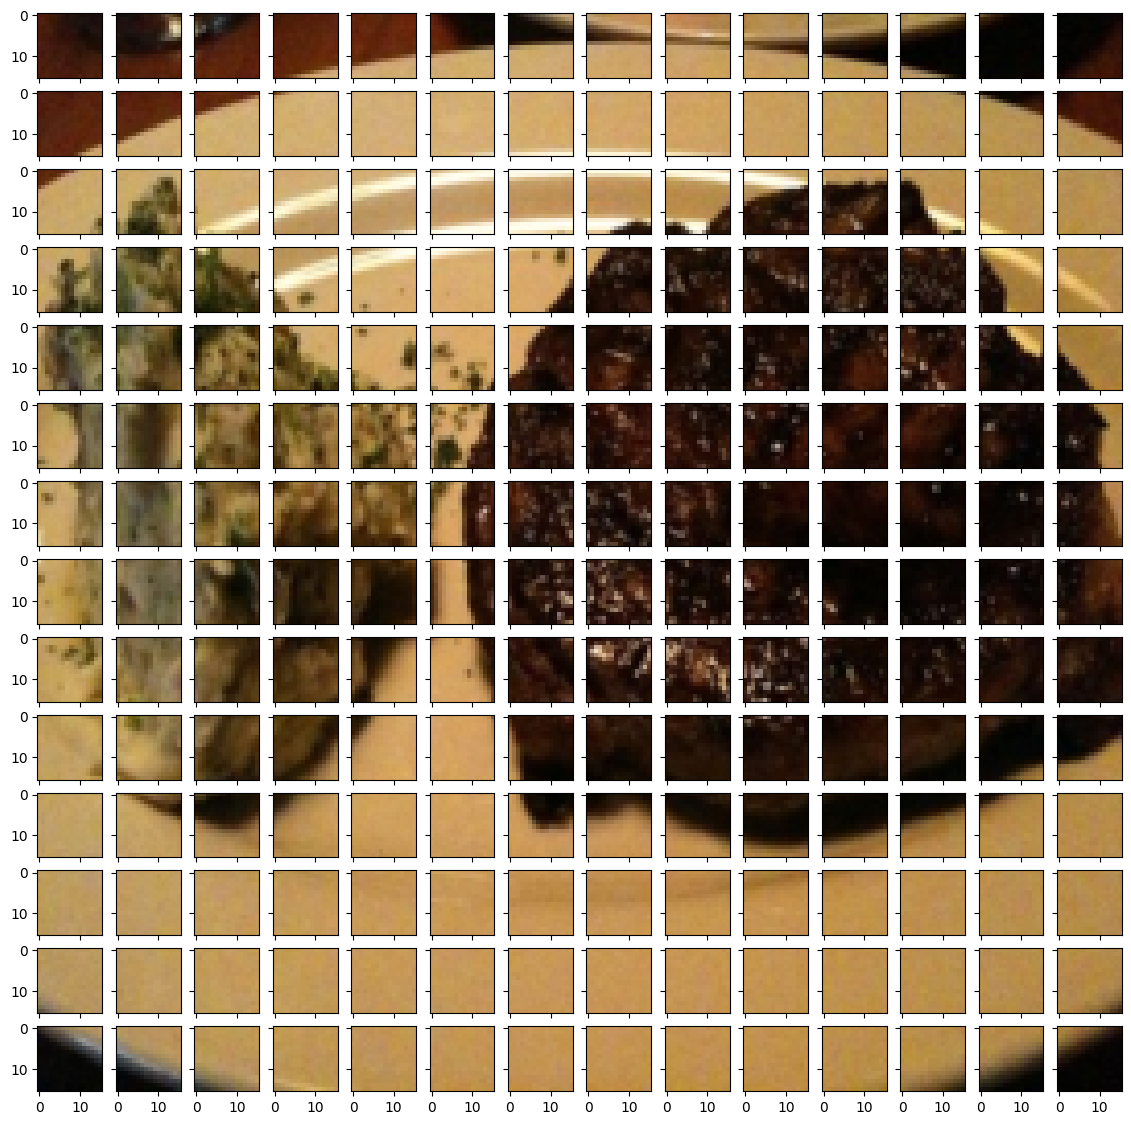

In [22]:
# Setup code to plot whole image as patches
img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\nNumber of patches per column: {num_patches}\nTotal patches: {num_patches*num_patches}\nPatch size: {patch_size} pixels x {patch_size} pixels")

# Create a series of subplots
fig, axs = plt.subplots(nrows=img_size // patch_size,
                        ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# Loop through height and width of image
for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
    for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width
        # Plot the permuted image on the different axes
        axs[i, j].imshow(permute_image[patch_height:patch_height+patch_size, # iterate through height
                                       patch_width:patch_width+patch_size, # iterate through width
                                       :]) # get all color channels

الـ Embedding باختصار هو ترجمة كل مربع صورة إلى "سلسلة أرقام (Vector)"، لكي يصبح شكل البيانات قادراً على دخول الـ Transformer تماماً مثلما ندخل الكلمات والجمل في معالجة اللغات الطبيعية (NLP)!

### turn image patches into patch embedding

In [23]:
from torch import nn
patch_size = 16
conv2d = nn.Conv2d(in_channels = 3, # number of color channels
                   out_channels = 768, # D size from table 1 
                   kernel_size = patch_size,
                   stride = patch_size,
                   padding = 0)
conv2d

Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))

Text(0.5, 1.0, 'steak')

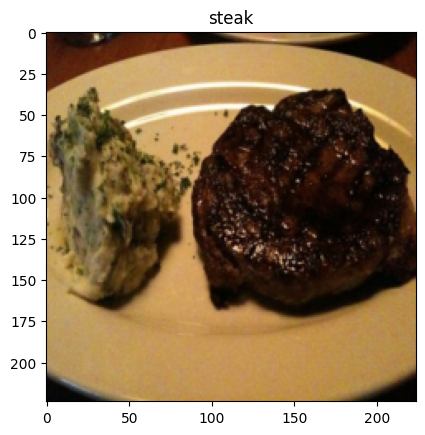

In [24]:
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])

In [25]:
# pass the image through conv layer
image_out_of_conv = conv2d(image.unsqueeze(0))
image_out_of_conv.shape

torch.Size([1, 768, 14, 14])

In [26]:
image_out_of_conv.requires_grad # learnable

True

In [27]:
image_out_of_conv #هذه الأرقام هي القيم العددية (Embeddings / Feature Maps)
# these values will update performing better representation of our image over time

tensor([[[[-1.3810e-01, -1.2224e-01, -2.1472e-01,  ..., -1.4931e-02,
           -8.0220e-02, -8.1360e-02],
          [-1.1996e-01, -1.9866e-01, -3.6748e-01,  ..., -4.1188e-01,
           -3.4874e-01, -1.7915e-01],
          [-2.3857e-01, -2.8318e-01, -4.6647e-01,  ..., -4.5692e-01,
           -3.3406e-01, -3.7031e-01],
          ...,
          [-3.8866e-01, -3.8573e-01, -3.9335e-01,  ..., -3.5891e-01,
           -3.7138e-01, -3.4821e-01],
          [-3.9860e-01, -4.0040e-01, -3.7670e-01,  ..., -3.4766e-01,
           -3.5688e-01, -3.3274e-01],
          [-2.0033e-02, -2.9982e-01, -4.1921e-01,  ..., -3.3798e-01,
           -2.0328e-01, -1.0108e-01]],

         [[ 5.4301e-02,  2.7599e-02,  6.2040e-02,  ..., -1.1237e-02,
            3.5447e-02,  5.3975e-02],
          [ 1.0439e-01,  4.8400e-02,  9.1039e-02,  ..., -2.3223e-02,
            1.8678e-01,  8.6030e-03],
          [-5.3389e-02, -1.6782e-03, -5.4614e-02,  ..., -1.2250e-01,
           -2.0879e-02, -3.7058e-03],
          ...,
     

Showing random convolutional feature maps from indexes: [407, 339, 378, 508, 439]


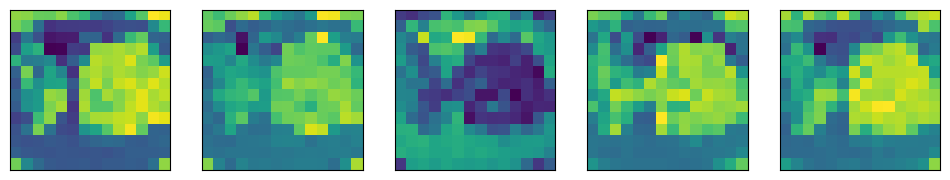

In [28]:
# plot random convolutional feature maps (embeddings)
import random
random_indexes = random.sample(range(0, 768), k=5)
print(f"Showing random convolutional feature maps from indexes: {random_indexes}")

# Create plot
fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(12, 12))

# Plot random image feature maps
for i, idx in enumerate(random_indexes):
    image_conv_feature_map = image_out_of_conv[:, idx, :, :] # index on the output tensor
    axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy()) # remove batch dimension and plot
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
    
# example of 5 feature maps with size 14 * 14 

In [29]:
image_out_of_conv.shape

torch.Size([1, 768, 14, 14])

In [30]:
#flatten the patch embedding 
#feature maps with size 14 * 14  turn it into size 196

from torch import nn
flatten_layer = nn.Flatten(start_dim = 2,
                           end_dim = 3)
image_out_of_conv_flatten = flatten_layer(image_out_of_conv)
image_out_of_conv_flatten.shape
#. (1, 768, 14, 14) --> (1, 768, 196)

torch.Size([1, 768, 196])

In [31]:
#rearranged 
# we finally have the input for our transformer encoder
image_out_of_conv_flatten_permuted = image_out_of_conv_flatten.permute(0, 2, 1)
print(f"{image_out_of_conv_flatten_permuted.shape} (batch size, number of patches, embedding dimension)")

torch.Size([1, 196, 768]) (batch size, number of patches, embedding dimension)


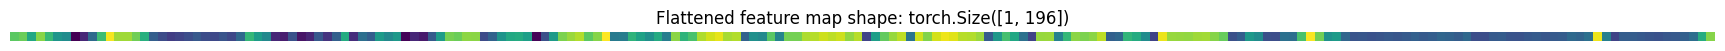

In [32]:
# Get a single flattened feature map
single_flattened_feature_map = image_out_of_conv_flatten_permuted[:, :, 0]

# Plot the flattened feature map visually
plt.figure(figsize=(22, 22))
plt.imshow(single_flattened_feature_map.detach().numpy())
plt.title(f"Flattened feature map shape: {single_flattened_feature_map.shape}")
plt.axis(False);

In [33]:
# لنفترض أننا نريد رؤية المتجه الخاص بالباتش الأول (رقم 0)
single_patch_vector = image_out_of_conv_flatten_permuted[0, 0, :] # (Batch=0, Patch=0, Embedding_dim=768)

print(f"شكل المتجه: {single_patch_vector.shape}")
print(f"أول 10 أرقام من الـ 768 رقماً لهذا الباتش:\n {single_patch_vector[:10]}")

شكل المتجه: torch.Size([768])
أول 10 أرقام من الـ 768 رقماً لهذا الباتش:
 tensor([-0.1381,  0.0543,  0.1247, -0.0415,  0.2139,  0.0968, -0.0216, -0.1189,
         0.0060,  0.0635], grad_fn=<SliceBackward0>)


In [34]:
#تجهيز ال patch embedding
class PatchEmbedding(nn.Module):
    def __init__(self,
                 in_channels:int= 3,
                 patch_size:int= 16,
                 embedding_dim:int = 768 ):
        super().__init__()
        
        self.patch_size = patch_size
        
        #طبقة التقطيع والتضمين
        self.patcher = nn.Conv2d(in_channels = in_channels,
                                 out_channels = embedding_dim,
                                 kernel_size = patch_size,
                                 stride = patch_size,
                                 padding = 0)
        
        #طبقة إعادة الترتيب والدمج
        self.flatten = nn.Flatten(start_dim = 2,
                                  end_dim = 3) 
        
    def forward(self, x):
        x_patched = self.patcher(x)
        x_flattened = self.flatten(x_patched)
        return x_flattened.permute(0, 2, 1) #(Batch Size, Number of Patches, Embedding Dimension)

In [35]:
patchify = PatchEmbedding(in_channels = 3,
                          patch_size = 16,
                          embedding_dim = 768)

print(f"input image size : {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0))
print(f"output patch embedding sequence shape: {patch_embedded_image.shape}")

input image size : torch.Size([1, 3, 224, 224])
output patch embedding sequence shape: torch.Size([1, 196, 768])


In [36]:
patch_embedded_image

tensor([[[ 6.5008e-02,  5.6280e-02, -1.0564e-01,  ...,  3.8025e-02,
          -7.4258e-02, -1.3122e-01],
         [-1.7736e-02,  1.8083e-02, -1.1785e-01,  ...,  6.2179e-02,
          -3.2093e-02,  1.3473e-02],
         [ 2.3000e-02,  4.0600e-02, -7.4783e-02,  ...,  5.5758e-02,
          -5.2693e-03, -1.3945e-01],
         ...,
         [ 2.6320e-01,  1.7973e-01, -7.9475e-02,  ..., -3.4950e-02,
           1.2834e-01, -3.2048e-01],
         [ 1.6860e-01,  2.4468e-01,  3.4756e-02,  ..., -1.5531e-01,
           2.1313e-01, -2.2296e-01],
         [ 1.1549e-01,  4.8314e-02, -8.8119e-02,  ..., -3.9001e-05,
           4.3483e-02, -8.0087e-02]]], grad_fn=<PermuteBackward0>)

In [37]:
# Get the batch size and embedding dimension
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]
batch_size, embedding_dimension

(1, 768)

In [38]:
import torch

In [39]:
#تجهيز ال class embedding
class_token = nn.Parameter(torch.ones(batch_size, 1, embedding_dimension),
                           requires_grad = True)
class_token.shape

#عبارة عن متجه (Vector) رقمي طوله يساوي أبعاد الـ Embedding.

torch.Size([1, 1, 768])

In [40]:
patch_embedded_image.shape

torch.Size([1, 196, 768])

In [41]:
patch_embedded_image_with_class_embedding = torch.cat((class_token, patch_embedded_image),
                                                      dim = 1)
patch_embedded_image_with_class_embedding

tensor([[[ 1.0000e+00,  1.0000e+00,  1.0000e+00,  ...,  1.0000e+00,
           1.0000e+00,  1.0000e+00],
         [ 6.5008e-02,  5.6280e-02, -1.0564e-01,  ...,  3.8025e-02,
          -7.4258e-02, -1.3122e-01],
         [-1.7736e-02,  1.8083e-02, -1.1785e-01,  ...,  6.2179e-02,
          -3.2093e-02,  1.3473e-02],
         ...,
         [ 2.6320e-01,  1.7973e-01, -7.9475e-02,  ..., -3.4950e-02,
           1.2834e-01, -3.2048e-01],
         [ 1.6860e-01,  2.4468e-01,  3.4756e-02,  ..., -1.5531e-01,
           2.1313e-01, -2.2296e-01],
         [ 1.1549e-01,  4.8314e-02, -8.8119e-02,  ..., -3.9001e-05,
           4.3483e-02, -8.0087e-02]]], grad_fn=<CatBackward0>)

In [42]:
patch_embedded_image_with_class_embedding.shape

torch.Size([1, 197, 768])

In [43]:
# تجهيز ال position embedding
number_of_patches = int((height*width) / patch_size**2)

embedding_dimension = patch_embedded_image_with_class_embedding.shape[-1]

position_embedding = nn.Parameter(torch.ones(1,
                                              number_of_patches+1,
                                              embedding_dimension),
                                   requires_grad = True)

In [44]:
position_embedding

Parameter containing:
tensor([[[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]]], requires_grad=True)

In [45]:
position_embedding.shape

torch.Size([1, 197, 768])

In [46]:
patch_and_position_embedding = patch_embedded_image_with_class_embedding + position_embedding
patch_and_position_embedding.shape

torch.Size([1, 197, 768])

In [47]:
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000e+00,  1.0000e+00,  1.0000e+00,  ...,  1.0000e+00,
            1.0000e+00,  1.0000e+00],
          [ 6.5008e-02,  5.6280e-02, -1.0564e-01,  ...,  3.8025e-02,
           -7.4258e-02, -1.3122e-01],
          [-1.7736e-02,  1.8083e-02, -1.1785e-01,  ...,  6.2179e-02,
           -3.2093e-02,  1.3473e-02],
          ...,
          [ 2.6320e-01,  1.7973e-01, -7.9475e-02,  ..., -3.4950e-02,
            1.2834e-01, -3.2048e-01],
          [ 1.6860e-01,  2.4468e-01,  3.4756e-02,  ..., -1.5531e-01,
            2.1313e-01, -2.2296e-01],
          [ 1.1549e-01,  4.8314e-02, -8.8119e-02,  ..., -3.9001e-05,
            4.3483e-02, -8.0087e-02]]], grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

In [48]:
patch_and_position_embedding, patch_and_position_embedding.shape
#هذا هو الذي يمثل صورتنا وسوف ندخله على ال ترانسفورمر 

(tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
          [1.0650, 1.0563, 0.8944,  ..., 1.0380, 0.9257, 0.8688],
          [0.9823, 1.0181, 0.8821,  ..., 1.0622, 0.9679, 1.0135],
          ...,
          [1.2632, 1.1797, 0.9205,  ..., 0.9650, 1.1283, 0.6795],
          [1.1686, 1.2447, 1.0348,  ..., 0.8447, 1.2131, 0.7770],
          [1.1155, 1.0483, 0.9119,  ..., 1.0000, 1.0435, 0.9199]]],
        grad_fn=<AddBackward0>),
 torch.Size([1, 197, 768]))

In [49]:
#build MSA block (فهم العلاقات والعلاقة بين الأجزاء")
class MultiHeadSelfAttention(nn.Module):
    def __init__(self,
                 embedding_dim:int = 768,
                 num_heads:int = 12,
                 attn_dropout:float = 0):
        super().__init__()
        self.layer_norm = nn.LayerNorm(normalized_shape = embedding_dim)
        self.multihead_attn = nn.MultiheadAttention(embed_dim = embedding_dim,
                                                    num_heads = num_heads,
                                                    dropout = attn_dropout,
                                                    batch_first = True)
    def forward(self, x):
        x = self.layer_norm(x)
        attn_output, _ = self.multihead_attn(query=x,
                                          key=x,
                                          value=x,
                                          need_weights=False)
        return attn_output

In [50]:
multihead_self_attention_block = MultiHeadSelfAttention(embedding_dim = 768,
                                                        num_heads = 12,
                                                        attn_dropout = 0)
patched_image_through_msa_block = multihead_self_attention_block(patch_and_position_embedding)
print(f"Input shape of MSA block: {patch_and_position_embedding.shape}")
print(f"Output shape of MSA block: {patched_image_through_msa_block.shape}")
#the shape didn't change but the value did

Input shape of MSA block: torch.Size([1, 197, 768])
Output shape of MSA block: torch.Size([1, 197, 768])


In [51]:
patch_and_position_embedding

tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
         [1.0650, 1.0563, 0.8944,  ..., 1.0380, 0.9257, 0.8688],
         [0.9823, 1.0181, 0.8821,  ..., 1.0622, 0.9679, 1.0135],
         ...,
         [1.2632, 1.1797, 0.9205,  ..., 0.9650, 1.1283, 0.6795],
         [1.1686, 1.2447, 1.0348,  ..., 0.8447, 1.2131, 0.7770],
         [1.1155, 1.0483, 0.9119,  ..., 1.0000, 1.0435, 0.9199]]],
       grad_fn=<AddBackward0>)

In [52]:
patched_image_through_msa_block

tensor([[[-0.1939,  0.0960, -0.6583,  ...,  0.6029, -0.3089,  0.2045],
         [-0.2151,  0.0973, -0.6551,  ...,  0.6079, -0.3021,  0.2176],
         [-0.1942,  0.0903, -0.6588,  ...,  0.6025, -0.2995,  0.2058],
         ...,
         [-0.2033,  0.0929, -0.6576,  ...,  0.6061, -0.3045,  0.2046],
         [-0.1932,  0.0964, -0.6469,  ...,  0.6011, -0.3133,  0.2066],
         [-0.1994,  0.1086, -0.6464,  ...,  0.6010, -0.3246,  0.2172]]],
       grad_fn=<TransposeBackward0>)

الـ MSA أولاً: تربط الباتشات ببعضها وتجعل كل جزء في الصورة "يرى" بقية الأجزاء.

الـ MLP ثانياً: تعالج المخرجات الناتجة من الـ MSA وتفهم تفاصيلها بشكل أعمق.

In [53]:
#build MLP block (معالجة المعلومات واستخلاص المعنى)
class MLPBlock(nn.Module):
    def __init__(self,
                 embedding_dim:int = 768,
                 mlp_size:int = 3072,
                 dropout:float = 0.1):
        super().__init__()
        self.layer_norm = nn.LayerNorm(normalized_shape = embedding_dim)
        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim,
                      out_features=mlp_size),
            nn.GELU(),
            nn.Dropout(p = dropout),
            nn.Linear(in_features = mlp_size,
                      out_features = embedding_dim),
            nn.Dropout(p = dropout)
        )
        
    def forward(self, x):
        x = self.layer_norm(x)
        x = self.mlp(x)
        return x
        #return self.mlp(self.layer_norm(x ))

In [54]:
mlp_block = MLPBlock(embedding_dim = 768,
                     mlp_size = 3072,
                     dropout = 0.1)
patched_image_through_mlp_block = mlp_block(patched_image_through_msa_block) 
print(f"Input shape of MLP block: {patched_image_through_msa_block.shape}")  
print(f"Output shape of MLP block: {patched_image_through_mlp_block.shape}")

Input shape of MLP block: torch.Size([1, 197, 768])
Output shape of MLP block: torch.Size([1, 197, 768])


In [55]:
patched_image_through_msa_block

tensor([[[-0.1939,  0.0960, -0.6583,  ...,  0.6029, -0.3089,  0.2045],
         [-0.2151,  0.0973, -0.6551,  ...,  0.6079, -0.3021,  0.2176],
         [-0.1942,  0.0903, -0.6588,  ...,  0.6025, -0.2995,  0.2058],
         ...,
         [-0.2033,  0.0929, -0.6576,  ...,  0.6061, -0.3045,  0.2046],
         [-0.1932,  0.0964, -0.6469,  ...,  0.6011, -0.3133,  0.2066],
         [-0.1994,  0.1086, -0.6464,  ...,  0.6010, -0.3246,  0.2172]]],
       grad_fn=<TransposeBackward0>)

In [56]:
patched_image_through_mlp_block

tensor([[[-0.2416, -0.1011, -0.2477,  ..., -0.1357, -0.0535, -0.0000],
         [-0.2858, -0.0042, -0.2599,  ..., -0.0000, -0.0000, -0.0000],
         [-0.1426, -0.1749, -0.3063,  ..., -0.2129, -0.1089, -0.2065],
         ...,
         [-0.2901, -0.2994, -0.3182,  ..., -0.0000, -0.0000, -0.1667],
         [-0.0000, -0.0702, -0.2394,  ..., -0.1455,  0.0205, -0.1800],
         [-0.1516,  0.0466, -0.0000,  ..., -0.0905, -0.0276, -0.2328]]],
       grad_fn=<MulBackward0>)

In [57]:
#Combine MSA and MLP block to create the Transformer
class TransformerEncoderBlock(nn.Module):
    def __init__(self,
                 embedding_dim:int = 768,
                 num_heads:int = 12,
                 mlp_size:int = 3072,
                 mlp_dropout:float = 0.1,
                 attn_dropout:float = 0):
        super().__init__()
        self.msa_block = MultiHeadSelfAttention(embedding_dim = embedding_dim,
                                                num_heads = num_heads,
                                                attn_dropout = attn_dropout)
        self.mlp_block = MLPBlock(embedding_dim = embedding_dim,
                                  mlp_size = mlp_size,
                                  dropout = mlp_dropout)
        
    def forward(self, x):
        x = self.msa_block(x) + x # add the Residual Connection
        x= self.mlp_block(x) + x # add the Residual Connection
        return x

In [58]:
transformer_encoder_block = TransformerEncoderBlock()

In [59]:
from torchinfo import summary
summary(
    model=transformer_encoder_block,
    input_size=(1,197,768,),  # (batch_size, number_of_patches, embedding_dimension)
    col_names=["input_size", "output_size", "num_params", "trainable"],
    col_width=20,
    row_settings=["var_names"],
)

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiHeadSelfAttention (msa_block)               [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multihead_attn)         --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

In [60]:
#built-in transformer in pytorch
torch_transformer_encoder_layer = torch.nn.TransformerEncoderLayer(d_model=768,  # embedding size from table 1
                                                            nhead=12,  # heads from table 1
                                                            dim_feedforward=3072,  # MLP size from table 1
                                                            dropout=0.1,
                                                            activation="gelu",
                                                            batch_first=True,
                                                            norm_first=True)
torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

In [61]:
from torchinfo import summary
summary(
    model=torch_transformer_encoder_layer,
    input_size=(1,197,768,),  # (batch_size, number_of_patches, embedding_dimension)
    col_names=["input_size", "output_size", "num_params", "trainable"],
    col_width=20,
    row_settings=["var_names"],
)

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        7,087,872            True
Total params: 7,087,872
Trainable params: 7,087,872
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0
Input size (MB): 0.61
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.61

### putting it all together to create VIT

In [62]:
class ViT(nn.Module):
  def __init__(self,
               img_size: int=224, # Table 3 from the ViT paper
               in_channels: int=3,
               patch_size: int=16,
               num_transformer_layers: int=12, # Table 1 for "Layers" for ViT-Base
               embedding_dim: int=768, # Hidden size D from Table 1 for ViT-Base
               mlp_size: int=3072, # Table 1
               num_heads: int=12, # Table 1
               attn_dropout: float=0,
               mlp_dropout: float=0.1,
               embedding_dropout: float=0.1, # Dropout for patch and position embeddings
               num_classes: int=1000): # number of classes in our classification problem
    super().__init__()
    
    # Make an assertion that the image size is compatible with the patch size
    assert img_size % patch_size == 0, f"Image size must be divisible by patch size, image: {img_size}, patch size: {patch_size}"
    
    # Calculate the number of patches (height * width / patch^2)
    self.num_patches = (img_size * img_size) // patch_size**2
    
    # Create learnable class embedding (needs to go at front of sequence of patch embeddings)
    self.class_embedding = nn.Parameter(data=torch.randn(1, 1, embedding_dim),
                                        requires_grad=True)
    
    # Create learnable position embedding
    self.position_embedding = nn.Parameter(data=torch.randn(1, self.num_patches + 1, embedding_dim))
    
    # Create embedding dropout value
    self.embedding_dropout = nn.Dropout(p=embedding_dropout)
    
    # Create patch embedding layer
    self.patch_embedding = PatchEmbedding(in_channels=in_channels,
                                          patch_size=patch_size,
                                          embedding_dim=embedding_dim)
    
    # Create the Transformer Encoder block
    self.transformer_encoder = nn.Sequential(*[TransformerEncoderBlock(embedding_dim=embedding_dim,
                                                                        num_heads=num_heads,
                                                                        mlp_size=mlp_size,
                                                                        mlp_dropout=mlp_dropout) for _ in range(num_transformer_layers)])
    
    # Create classifier head
    self.classifier = nn.Sequential(
        nn.LayerNorm(normalized_shape=embedding_dim),
        nn.Linear(in_features=embedding_dim,
                  out_features=num_classes)
    )
    
  def forward(self, x):
    # Get the batch size
    batch_size = x.shape[0]
    
    # Create class token embedding and expand it to match the batch size (equation 1)
    class_token = self.class_embedding.expand(batch_size, -1, -1) # "-1" means to infer the dimensions
    
    # Create the patch embedding (equation 1)
    x = self.patch_embedding(x)
    
    # Concat class token embedding and patch embedding (equation 1)
    x = torch.cat((class_token, x), dim=1) # (batch_size, number_of_patches, embedding_dim)
    
    # Add position embedding to class token and patch embedding
    x = self.position_embedding + x
    
    # Apply dropout to patch embedding ("directly after adding positional- to patch embeddings")
    x = self.embedding_dropout(x)
    
    # Pass position and patch embedding to Transformer Encoder (equation 2 & 3)
    x = self.transformer_encoder(x)
    
    # Put 0th (variable) classifier: Sequential equation 4)
    x = self.classifier(x[:, 0])
    
    return x

In [63]:
batch_size = 32
embedding_dim = 768
class_embedding = nn.Parameter(
    data=torch.randn(1, 1, embedding_dim), requires_grad=True
)
class_embedding_expanded = class_embedding.expand(batch_size, -1, -1)
print(class_embedding.shape)
print(class_embedding_expanded.shape)

torch.Size([1, 1, 768])
torch.Size([32, 1, 768])


In [64]:
vit = ViT()
vit

ViT(
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (patch_embedding): PatchEmbedding(
    (patcher): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (flatten): Flatten(start_dim=2, end_dim=3)
  )
  (transformer_encoder): Sequential(
    (0): TransformerEncoderBlock(
      (msa_block): MultiHeadSelfAttention(
        (layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
      )
      (mlp_block): MLPBlock(
        (layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (1)

In [65]:
torch.manual_seed(42)

# Create a random image tensor with same shape as a single image
random_image_tensor = torch.randn(1, 3, 224, 224)

# Create an instance of ViT with the number of classes we're working with (pizza, steak and sushi)
vit = ViT(num_classes=len(class_names))

# Pass the random image tensor to our ViT instance
vit(random_image_tensor)

#the output is in logits representation

tensor([[-0.2377,  0.7360,  1.2137]], grad_fn=<AddmmBackward0>)

In [66]:
from torchinfo import summary

summary(
    model=ViT(num_classes=len(class_names)),
    input_size=(1, 3, 224, 224),  # (batch_size, color_channels, height, width)
    col_names=["input_size", "output_size", "num_params", "trainable"],
    col_width=20,
    row_settings=["var_names"],
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                                    [1, 3, 224, 224]     [1, 3]               152,064              True
├─PatchEmbedding (patch_embedding)                           [1, 3, 224, 224]     [1, 196, 768]        --                   True
│    └─Conv2d (patcher)                                      [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
│    └─Flatten (flatten)                                     [1, 768, 14, 14]     [1, 768, 196]        --                   --
├─Dropout (embedding_dropout)                                [1, 197, 768]        [1, 197, 768]        --                   --
├─Sequential (transformer_encoder)                           [1, 197, 768]        [1, 197, 768]        --                   True
│    └─TransformerEncoderBlock (0)                           [1, 197, 768]        [1, 197, 768] 

### start training

In [67]:
#set an optimizer (in vit paper they used adam optimizer)
optimizer = torch.optim.Adam(
    vit.parameters(),
    lr=1e-3,
    betas=(0.9, 0.999),
    weight_decay=0.1 #Regularization technique to prevent overfitting
)

In [68]:
#set a loss function (the loss function not mentioned in vit paper)
loss_fn = torch.nn.CrossEntropyLoss() #for multi-class classification

In [69]:
#create train loop
def train_step(model:torch.nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               optimizer:torch.optim.Optimizer):
    model.train()
    train_loss, train_acc = 0, 0
    
    for batch, (X, y) in enumerate(dataloader):
        y_pred = model(X)
        loss= loss_fn(y_pred, y)
        train_loss += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)
        
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    print(f"train loss : {train_loss:.5f} | train acc : {train_acc * 100:.2f}%")

In [70]:
#create test loop
def test_step(model:torch.nn.Module,
              dataloader:torch.utils.data.DataLoader,
              loss_fn:torch.nn.Module):
    model.eval()
    test_loss, test_acc = 0, 0
    
    with torch.inference_mode():
        for batch, (X, y) in enumerate(dataloader):
            test_pred_logits = model(X)
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()  
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += (test_pred_labels == y).sum().item() / len(test_pred_labels)
            
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc /len(dataloader)
    print(f"test loss : {test_loss:.5f} | test acc : {test_acc * 100:.2f}%")

In [ ]:
from tqdm.auto import tqdm
torch.manual_seed(42)

epochs = 10

for epoch in tqdm(range(epochs)):
    print(f"epoch : {epoch}")
    train_step(model = vit,
               dataloader = train_dataloader,
               loss_fn = loss_fn,
               optimizer = optimizer)
    test_step(model = vit,
              dataloader = test_dataloader,
              loss_fn = loss_fn)
    
# Training on CPU on purpose: on this Mac (Intel + Radeon Pro 555X, 4GB) MPS ran out of memory
# with batch size 32 and 16, and with batch size 8 it was much slower than CPU (~3 min per epoch).

  0%|          | 0/10 [00:00<?, ?it/s]

epoch : 0


train loss : 4.86640 | train acc : 27.73%


 10%|█         | 1/10 [03:43<33:29, 223.31s/it]

test loss : 1.04922 | test acc : 54.17%
epoch : 1
train loss : 1.49323 | train acc : 32.42%


...

test loss : 1.14850 | test acc : 54.17%
epoch : 8
train loss : 1.39672 | train acc : 28.91%


 90%|█████████ | 9/10 [38:07<03:57, 237.76s/it]

test loss : 1.08443 | test acc : 26.04%
epoch : 9
train loss : 1.14122 | train acc : 43.36%


100%|██████████| 10/10 [40:55<00:00, 245.55s/it]

test loss : 1.14915 | test acc : 54.17%


## What our training setup is missing

How is our training setup different to the ViT paper?

We've replicated model architecture correctly.

But what was different between our training procedure (to get such poor results) and the ViT paper training procedure to get such great results?

The main things our training implementation is missing:

Prevent underfitting:
* Data - our setup uses far less data (225 vs millions)

Prevent overfitting:
* Learning rate warmup - start with a low learning rate and increase to a base LR
* Learning rate decay - as your model gets closer to convergence, start to lower the learning rate
* Gradient clipping - prevent gradients from getting too big

Search "pytorch [technique name]"